Good day!

Before running the notebook, you must;

1. Have ngrok available and replace {Your_ngrok_key_here} with your own Authkey

2. Download this dataset by Puru Singhvi [Spam Email Classification Dataset](https://www.kaggle.com/datasets/purusinghvi/email-spam-classification-dataset)

In [ ]:
## One time install (Only need to run once)

!pip install flask_ngrok
!pip install --upgrade pyngrok flask
!pip install pyngrok
!python -m nltk.downloader punkt wordnet stopwords punkt_tab

# **Library imports & ngrok**



*   This cell is just to run any necessary imports for the project to work, like the Machine Learning algorithms and preprocessing.



In [ ]:
from flask_ngrok import run_with_ngrok
from flask import Flask, render_template_string
from pyngrok import ngrok # Added this import statement


import matplotlib
matplotlib.use('Agg')  # Prevents GUI thread crashes inside Flask
import matplotlib.pyplot as plt
import os
import pandas as pd
import string
import nltk
import shap
import seaborn as sns
import numpy as np
import io
import base64
from flask import Flask, render_template_string, request
from pyngrok import ngrok
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.neural_network import MLPClassifier ## Neural Network
from sklearn.metrics import classification_report, accuracy_score, recall_score, f1_score, precision_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

nltk.download('punkt')
nltk.download('wordnet')
nltk.download('stopwords')
nltk.download('punkt_tab')

NGROK_AUTH_TOKEN = "{Your_ngrok_key_here}"
ngrok.set_auth_token(NGROK_AUTH_TOKEN)

# **NLTK & Text preprocessing**


*   This cell runs the preprocessing steps, turning unnecessary word clutter into its simplest/root form.
(i.e: Scamming to scam)



In [ ]:
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))


def preprocess_text(text):
    text = str(text).lower().translate(str.maketrans('', '', string.punctuation))
    tokens = word_tokenize(text)
    return " ".join([lemmatizer.lemmatize(w) for w in tokens if w not in stop_words and w.isalpha()])

# **Model Training**


*   This cell is the model training for MultinomialNB and MultiLayerPerceptron(NN), utilizing 5000 features from the dataset for the model to learn from.



In [ ]:
print("Training models... please wait.")
df = pd.read_csv('combined_data.csv').dropna(subset=['text', 'label'])
df['text_processed'] = df['text'].apply(preprocess_text)

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X = tfidf.fit_transform(df['text_processed'])
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

nb_model = MultinomialNB().fit(X_train, y_train)
nn_model = MLPClassifier(hidden_layer_sizes=(50,), max_iter=100, random_state=42).fit(X_train, y_train)
print("Models ready!")

# **SHapley Additive Explainations**


*   The explainable AI that will give the user a better explaination as to why the results are the way they are. Reducing uncertainty in the results



In [ ]:
print("SHAP Loading")
# Build a localized background dataset slice from the training collection
X_train_sample = X_train[:20].toarray()

### SHAP Training
nb_explainer = shap.KernelExplainer(lambda x: nb_model.predict_proba(x)[:, 1], X_train_sample)
nn_explainer = shap.KernelExplainer(lambda x: nn_model.predict_proba(x)[:, 1], X_train_sample)
print("SHAP explainers ready!")

# **Flask Website frontend & Text prediction decision making**


*   The main website, wherein the user copy and pastes an email in order to determine spam (Malicious) or ham (Safe).



In [ ]:
app = Flask(__name__)

HTML_UI = """
<!DOCTYPE html>
<html>
<head>
    <title>AI Spam Shield</title>
    <style>
        body { font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; background-color: #0e1117; color: #ffffff; display: flex; flex-direction: column; align-items: center; padding: 50px; }
        .container { background: #161b22; padding: 30px; border-radius: 15px; box-shadow: 0 8px 32px 0 rgba(0,0,0,0.8); width: 80%; max-width: 600px; }
        textarea { width: 100%; height: 150px; background: #0d1117; color: white; border: 1px solid #30363d; border-radius: 10px; padding: 15px; margin-bottom: 20px; box-sizing: border-box; font-size: 16px; }
        input[type="submit"] { background-color: #238636; color: white; border: none; padding: 12px 24px; border-radius: 6px; cursor: pointer; font-weight: bold; width: 100%; transition: 0.3s; }
        input[type="submit"]:hover { background-color: #2ea043; }
        .result-box { margin-top: 25px; padding: 20px; border-radius: 10px; text-align: center; border: 1px solid; }
        .spam { background-color: #442726; border-color: #f85149; color: #ff7b72; }
        .ham { background-color: #1a271d; border-color: #2ea043; color: #7ee787; }
        .shap-box { margin-top: 25px; padding: 20px; background: #0d1117; border-radius: 10px; border: 1px solid #30363d; text-align: center; }
        .shap-box img { width: 100%; border-radius: 8px; margin-top: 15px; border: 1px solid #30363d;}
    </style>
</head>
<body>
    <div class="container">
        <h2>Machine Learning Email Spam detector</h2>
        <form action="/predict" method="post">
            <textarea name="email_content" placeholder="Paste your email content here..." required>{{ original_text }}</textarea>
            <input type="submit" value="Check Security Status">
        </form>

        {% if prediction %}
            <div class="result-box {{ 'spam' if prediction == 'SPAM DETECTED' else 'ham' }}">
                <h3>{{ prediction }}</h3>
                <small style="opacity: 0.8;">Analyzed via: {{ model_used }}</small>
            </div>
        {% endif %}

        {% if shap_img %}
            <div class="shap-box">
                <h4> Decision Breakdown (Blackbox Inspection)</h4>
                <p style="font-size: 13px; color: #8b949e; margin: 5px 0;">
                    Words in <span style="color: #f85149; font-weight: bold;">Red</span> pushed the AI to flag it as SPAM.<br>
                    Words in <span style="color: #2ea043; font-weight: bold;">Green</span> argued it was safe (HAM).
                </p>
                <img src="data:image/png;base64,{{ shap_img }}" alt="SHAP Feature Importance Graph">
            </div>
        {% endif %}
    </div>
</body>
</html>
"""


@app.route("/")
def home():
    return render_template_string(HTML_UI, original_text="")


@app.route("/predict", methods=["POST"])
def predict():
    try:
        email_text = request.form.get("email_content")  ### This is where the pasted email gets sent
        processed = preprocess_text(email_text)

        # Message if text box = empty
        if not processed.strip():
            return render_template_string(
                HTML_UI,
                prediction="SHORT OR EMPTY INPUT",
                model_used="N/A",
                original_text=email_text
            )

        vectorized = tfidf.transform([processed])
        vectorized_dense = vectorized.toarray()

        nb_probs = nb_model.predict_proba(vectorized)[0]
        prob_ham, prob_spam = nb_probs[0], nb_probs[1]

        threshold = 0.90  ### The threshold for escalation decision
        if prob_spam >= threshold or prob_ham >= threshold:
            prediction = "SPAM DETECTED" if prob_spam >= threshold else "HAM (SAFE)"
            model_used = "Fast Filter (MultinomialNB)"
            raw_shap = nb_explainer.shap_values(vectorized_dense)
        else:
            nn_res = nn_model.predict(vectorized)[0]
            prediction = "SPAM DETECTED" if nn_res == 1 else "HAM (SAFE)"
            model_used = "Deep Inspector (Multi-Layer Perceptron)"
            raw_shap = nn_explainer.shap_values(vectorized_dense)

        # Handle array structures cleanly across varying SHAP package releases
        if isinstance(raw_shap, list):
            shap_values = raw_shap[1] if len(raw_shap) > 1 else raw_shap[0]
        else:
            shap_values = raw_shap[0] if raw_shap.ndim > 1 else raw_shap

        feature_names = tfidf.get_feature_names_out()

        # Map indices exclusively to terms present inside the analyzed string
        words_in_text = set(processed.split())
        matched_indices = [i for i, name in enumerate(feature_names) if name in words_in_text]

        # Use top global impact values as a contingency fallback
        if not matched_indices:
            matched_indices = np.argsort(np.abs(shap_values))[-10:].tolist()

        matched_indices = np.array(matched_indices)
        matched_indices = matched_indices[matched_indices < len(shap_values)]

        # Extract the top 10 keywords SHAP gave ###
        top_subset = matched_indices[np.argsort(np.abs(shap_values[matched_indices]))[-10:]]
        top_features = feature_names[top_subset]
        top_shap_vals = shap_values[top_subset]

        # Matplotlib Plot for SHAP
        fig, ax = plt.subplots(figsize=(7, 4), facecolor='#0d1117')
        ax.set_facecolor('#0d1117')

        # Red bar for spam markers, Green bar for safe features
        colors = ['#f85149' if val > 0 else '#2ea043' for val in top_shap_vals]
        ax.barh(top_features, top_shap_vals, color=colors, height=0.55)

        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_color('#30363d')
        ax.spines['bottom'].set_color('#30363d')
        ax.tick_params(colors='#ffffff', labelsize=11)
        ax.xaxis.grid(True, linestyle='--', alpha=0.15, color='#ffffff')
        ax.set_axisbelow(True)
        plt.xlabel("Impact on Spam Prediction", color='#8b949e', fontsize=10, labelpad=10)
        plt.title(f"Top Driving Words ({model_used})", color='#ffffff', fontsize=12, pad=12, fontweight='bold')

        # Convert plot data into a base64 string
        buf = io.BytesIO()
        plt.savefig(buf, format='png', bbox_inches='tight', dpi=140, facecolor=fig.get_facecolor())
        buf.seek(0)
        shap_img_base64 = base64.b64encode(buf.getvalue()).decode('utf-8')
        plt.close(fig)

        return render_template_string(
            HTML_UI,
            prediction=prediction,
            model_used=model_used,
            shap_img=shap_img_base64,
            original_text=email_text
        )

    except Exception as e:
        print(f"CRASH IN PREDICT: {e}")
        "Internal server error while processing request."

# **Start ngrok Tunnel & Run Flask Server**


*   Where the Flask website will be presented



In [ ]:
ngrok.kill()
public_url = ngrok.connect(5000).public_url
print(f" * Public URL: {public_url}")

if __name__ == '__main__':
    app.run(port=5000)

### **Here is an example of what's to be expected when running the program**



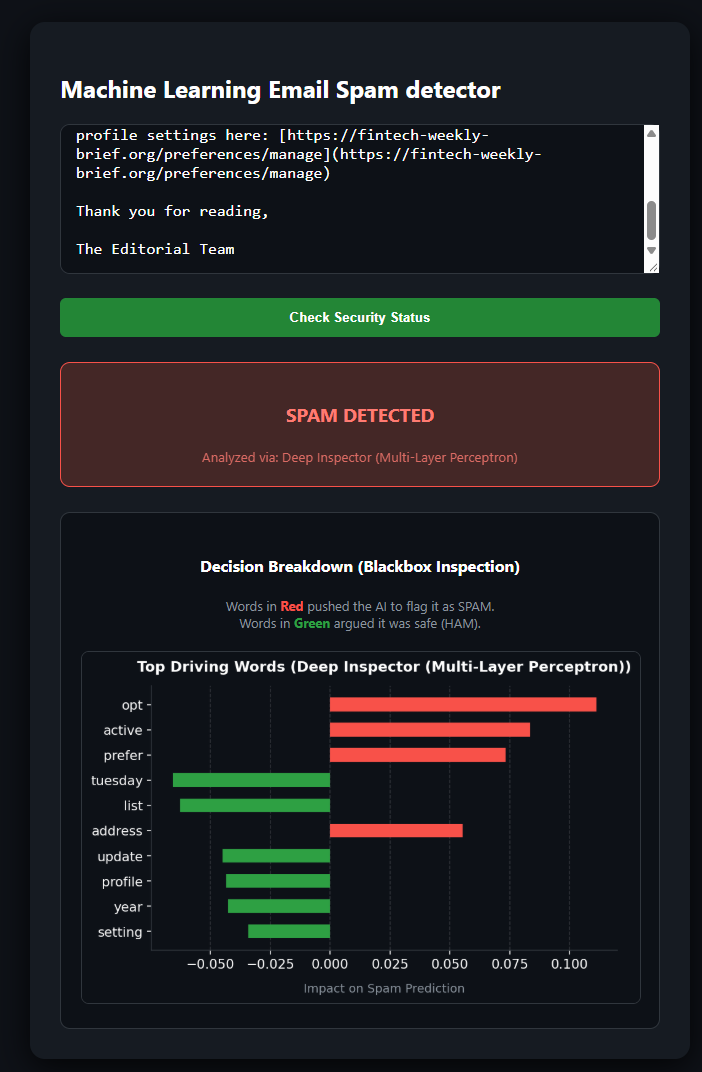